# 10. Visual Evaluation, Classical ADM Diagnostics & Distillation Audit

Notebook ini melengkapi kernel training Kaggle `01` hingga `09` yang berfokus pada eksekusi GPU tanpa overhead grafik. Seluruh angka, statistik multivariat, perbandingan model, uji ketahanan derau, kalibrasi, serta pratinjau visual pada notebook ini dijalankan langsung terhadap hasil empiris terverifikasi di `outputs/` dan `eval_results/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

try:
    from IPython.display import display
except ImportError:
    display = None

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIG_DIR = OUTPUTS_DIR / "presentation_figures"
EVAL_DIR = PROJECT_ROOT / "eval_results"

plt.rcParams.update({
    "figure.facecolor": "#FFFFFF",
    "axes.facecolor": "#F8FAFC",
    "axes.edgecolor": "#CBD5E1",
    "axes.grid": True,
    "grid.color": "#E2E8F0",
    "grid.linestyle": "--",
    "grid.alpha": 0.75,
    "font.size": 10.5,
})

diag = json.loads((OUTPUTS_DIR / "multivariate_diagnostics_summary.json").read_text(encoding="utf-8"))
bench = json.loads((OUTPUTS_DIR / "multivariate_benchmark_results.json").read_text(encoding="utf-8"))
verified = json.loads((EVAL_DIR / "verified_empirical_metrics.json").read_text(encoding="utf-8"))
df_subs = pd.read_csv(OUTPUTS_DIR / "master_all_submissions_audit.csv")

print(f"PROJECT_ROOT : {PROJECT_ROOT.name}")
print(f"Audit Rows   : {len(df_subs)} submissions (Sub 1..32 + Phase 2 Blind Test)")
print(f"Keynote PNGs : {len(list(FIG_DIR.glob('*.png')))} in outputs/presentation_figures/ + 4 root ADM plots")

PROJECT_ROOT : FinalProject
Audit Rows   : 28 submissions (Sub 1..32 + Phase 2 Blind Test)
Keynote PNGs : 20 in outputs/presentation_figures/ + 4 root ADM plots


## 1. Diagnostik Multivariat Klasik (PCA, MANOVA, Box's M & LDA vs QDA)

Menampilkan hasil dekomposisi spektral (`10.500` citra x `4.096` dimensi piksel), uji kesamaan vektor mean **MANOVA**, uji homogenitas kovarians **Box's M**, performa 5-Fold CV (`PCA+LDA` vs `PCA+QDA`), serta galeri 4 figur klasik ADM (`scree_plot.png`, `eigen_characters.png`, `mahalanobis_qq_plot.png`, `lda_canonical_projection.png`).

=== 1A. RINGKASAN STATISTIK MULTIVARIAT KLASIK (10.500 SAMPEL, 4.096 DIMENSI) ===
PCA Kaiser Criterion  : 275 komponen (threshold lambda=0.087497)
CPVE (Cumulative Var) : 80%=82, 85%=109, 90%=154, 95%=252 komponen
MANOVA (m=20 PCA)     : Wilks' Lambda=8.8900e-05 | Pillai=5.8418 | Hotelling=17.6700 | Partial Eta^2=0.4864
Box's M Test          : m=20 -> M=214,542.1 (p=0.0) | m=40 -> M=535,061.6 (p=0.0)

=== 1B. BENCHMARK KLASIFIKATOR 5-FOLD STRATIFIED GROUP K-FOLD ===
  - Two-Stage PCA (100) + LDA             :  85.13% +/- 2.00%
  - Two-Stage PCA (40) + QDA              :  96.09% +/- 0.98%
  - Two-Stage PCA (100) + Logistic Regression:  91.08% +/- 1.68%


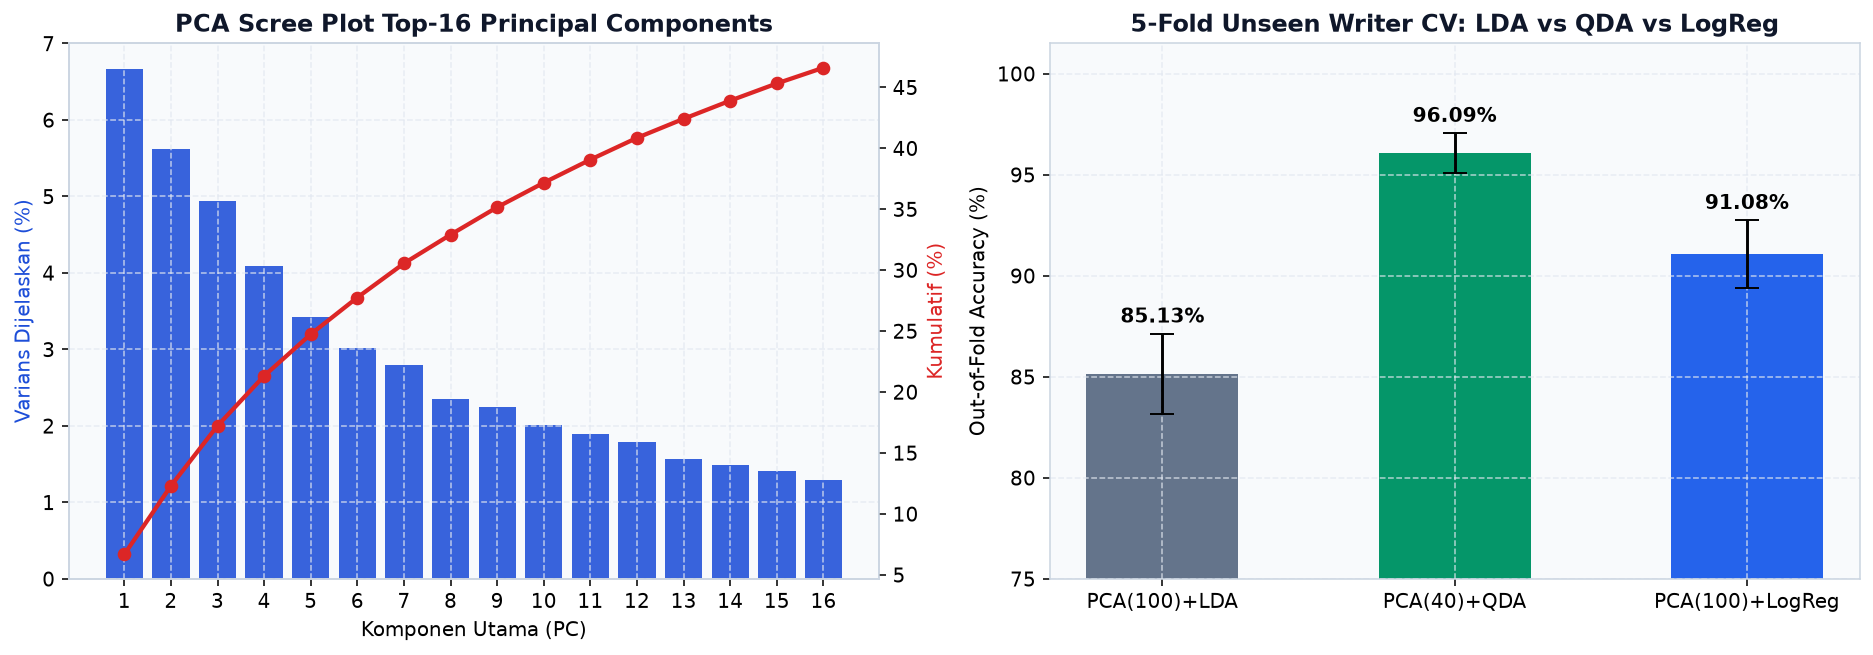

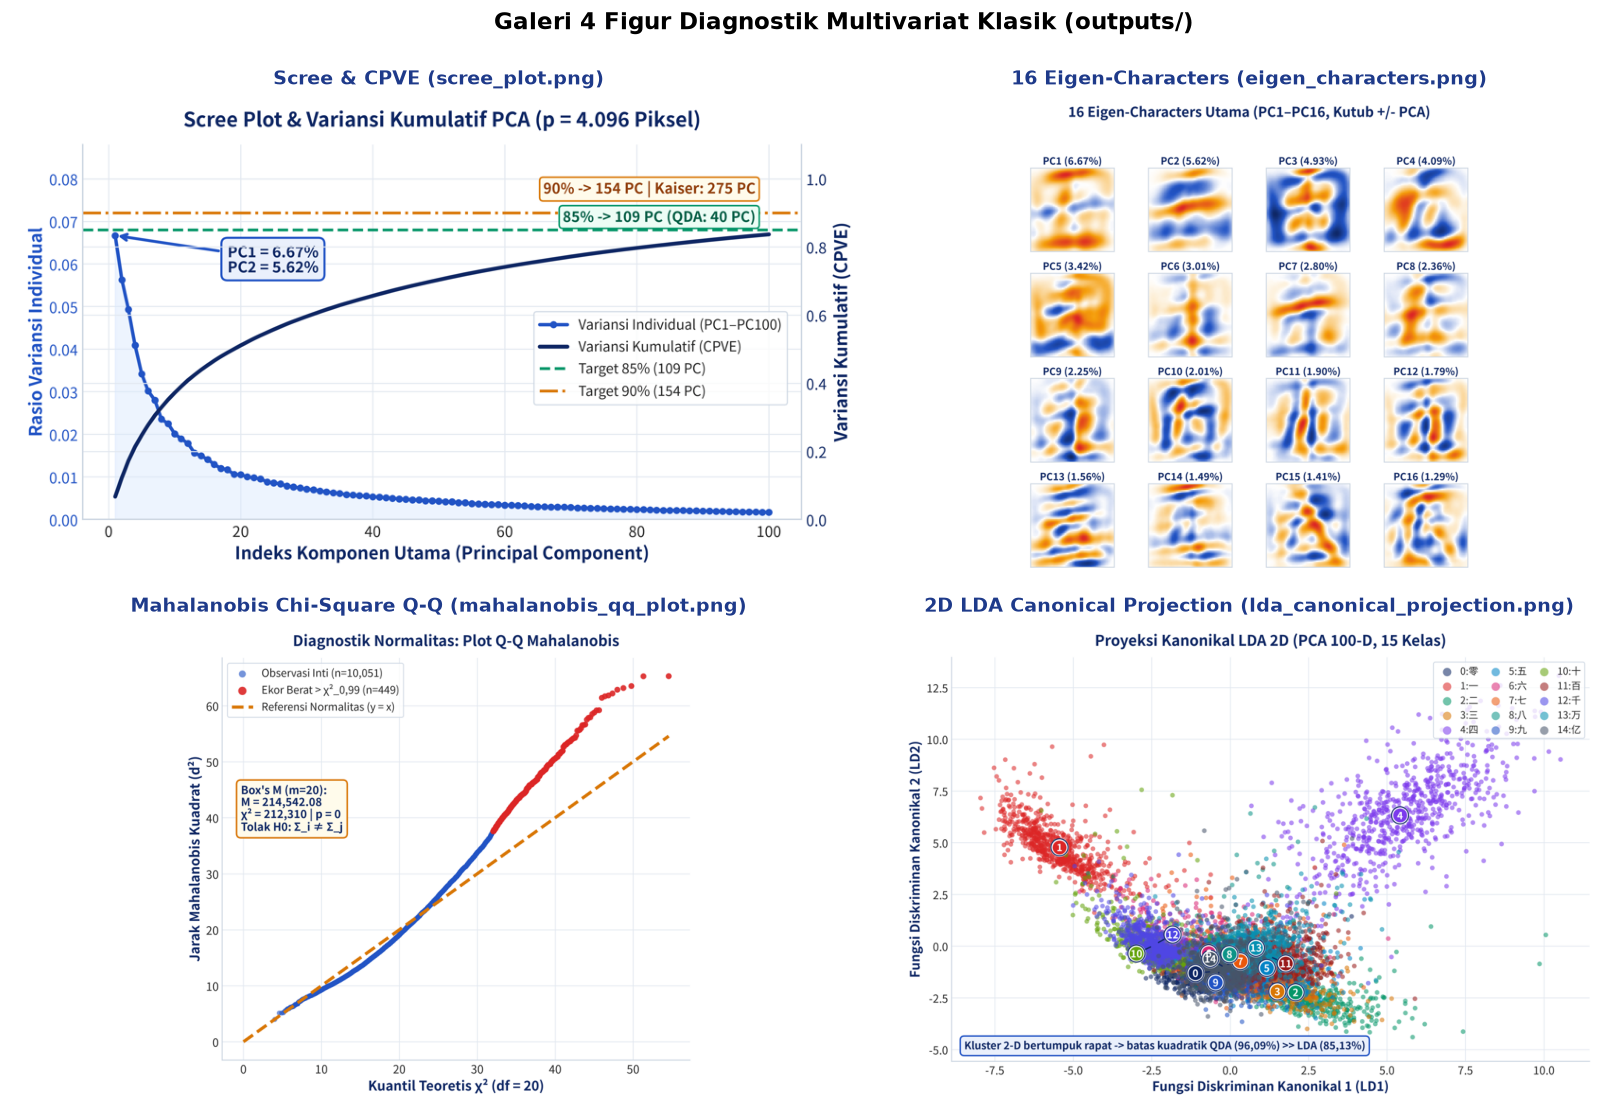

In [2]:
pca_info = diag["pca"]
manova = diag["manova_m20"]
box20 = manova["box_m"]
box40 = diag["box_m_m40"]

print("=== 1A. RINGKASAN STATISTIK MULTIVARIAT KLASIK (10.500 SAMPEL, 4.096 DIMENSI) ===")
print(f"PCA Kaiser Criterion  : {pca_info['kaiser_count']} komponen (threshold lambda={pca_info['kaiser_threshold']:.6f})")
print(
    f"CPVE (Cumulative Var) : 80%={pca_info['cpve_80_components']}, "
    f"85%={pca_info['cpve_85_components']}, 90%={pca_info['cpve_90_components']}, "
    f"95%={pca_info['cpve_95_components']} komponen"
)
print(
    f"MANOVA (m=20 PCA)     : Wilks' Lambda={manova['wilks_lambda']:.4e} | "
    f"Pillai={manova['pillai_trace']:.4f} | Hotelling={manova['hotelling_trace']:.4f} | "
    f"Partial Eta^2={manova['partial_eta_squared']:.4f}"
)
print(
    f"Box's M Test          : m=20 -> M={box20['box_m']:,.1f} (p={box20['p_value']}) | "
    f"m=40 -> M={box40['box_m']:,.1f} (p={box40['p_value']})"
)
print("\n=== 1B. BENCHMARK KLASIFIKATOR 5-FOLD STRATIFIED GROUP K-FOLD ===")
for name, stats in bench.items():
    print(f"  - {name:38s}: {stats['mean_accuracy']*100:6.2f}% +/- {stats['std_accuracy']*100:.2f}%")

# Plot ringkasan PCA Scree + Perbandingan Akurasi Klasik 5-Fold
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=140)
ev = pca_info["top_16_explained_variance_pct"]
pcs = np.arange(1, len(ev) + 1)
ax1.bar(pcs, ev, color="#1D4ED8", alpha=0.88, label="Varians PC Individual (%)")
ax1_twin = ax1.twinx()
ax1_twin.plot(pcs, np.cumsum(ev), color="#DC2626", marker="o", lw=2.2, label="Kumulatif Top-16 (%)")
ax1_twin.grid(False)
ax1.set_title("PCA Scree Plot Top-16 Principal Components", fontweight="bold", color="#0F172A")
ax1.set_xlabel("Komponen Utama (PC)")
ax1.set_ylabel("Varians Dijelaskan (%)", color="#1D4ED8")
ax1_twin.set_ylabel("Kumulatif (%)", color="#DC2626")
ax1.set_xticks(pcs)

models = list(bench.keys())
short_labels = ["PCA(100)+LDA", "PCA(40)+QDA", "PCA(100)+LogReg"]
means = [bench[m]["mean_accuracy"] * 100 for m in models]
stds = [bench[m]["std_accuracy"] * 100 for m in models]
colors = ["#64748B", "#059669", "#2563EB"]
bars = ax2.bar(short_labels, means, yerr=stds, capsize=6, color=colors, width=0.52)
ax2.set_ylim(75, 101.5)
ax2.set_title("5-Fold Unseen Writer CV: LDA vs QDA vs LogReg", fontweight="bold", color="#0F172A")
ax2.set_ylabel("Out-of-Fold Accuracy (%)")
for bar, val, sd in zip(bars, means, stds):
    ax2.text(bar.get_x() + bar.get_width() / 2, val + sd + 0.55, f"{val:.2f}%", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()

# Gabungkan 4 plot ADM asli dari outputs/ dalam panel 2x2 ringkas
adm_files = [
    ("Scree & CPVE", OUTPUTS_DIR / "scree_plot.png"),
    ("16 Eigen-Characters", OUTPUTS_DIR / "eigen_characters.png"),
    ("Mahalanobis Chi-Square Q-Q", OUTPUTS_DIR / "mahalanobis_qq_plot.png"),
    ("2D LDA Canonical Projection", OUTPUTS_DIR / "lda_canonical_projection.png"),
]
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.6), dpi=130)
for ax, (title, fpath) in zip(axes.flat, adm_files):
    img = Image.open(fpath).convert("RGB")
    img.thumbnail((900, 650))
    ax.imshow(img)
    ax.set_title(f"{title} ({fpath.name})", fontsize=10.5, fontweight="bold", color="#1E3A8A")
    ax.axis("off")
plt.suptitle("Galeri 4 Figur Diagnostik Multivariat Klasik (outputs/)", fontsize=12.5, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

## 2. Evolusi Akurasi CodaBench (Sub 1-32 Fase 1 & Blind Test Fase 2)

Memetakan lintasan eksperimen dari Era I hingga Single Distilled Student SWA FP16 (`Sub 32`: **99,84%** Fase 1; `P2-Sub1`: **98,62%** Fase 2) berdasarkan berkas audit resmi `outputs/master_all_submissions_audit.csv`.

=== TABEL LINTASAN SUBMISSION CODABENCH TERVERIFIKASI ===
 sub_num                                            filename                       status  total_correct  accuracy  acc_chinese  acc_gb_micro  acc_target_macro
       1                     submission_phase1_adabn_tta.csv           OFFICIAL_CODABENCH           2249    0.9120       0.9993        0.7764            0.7455
       2                        submission_phase1_anchor.csv           OFFICIAL_CODABENCH           2288    0.9278       0.9993        0.8168            0.7847
       3         submission_phase1_blend_resnet_convnext.csv           OFFICIAL_CODABENCH           2298    0.9319       1.0000        0.8261            0.7994
       4                    submission_phase1_hccr_senet.csv           OFFICIAL_CODABENCH           2163    0.8771       0.9967        0.6915            0.6661
       5                     submission_phase1_gated_moe.csv           OFFICIAL_CODABENCH           2290    0.9286       0.9993        0.8188 

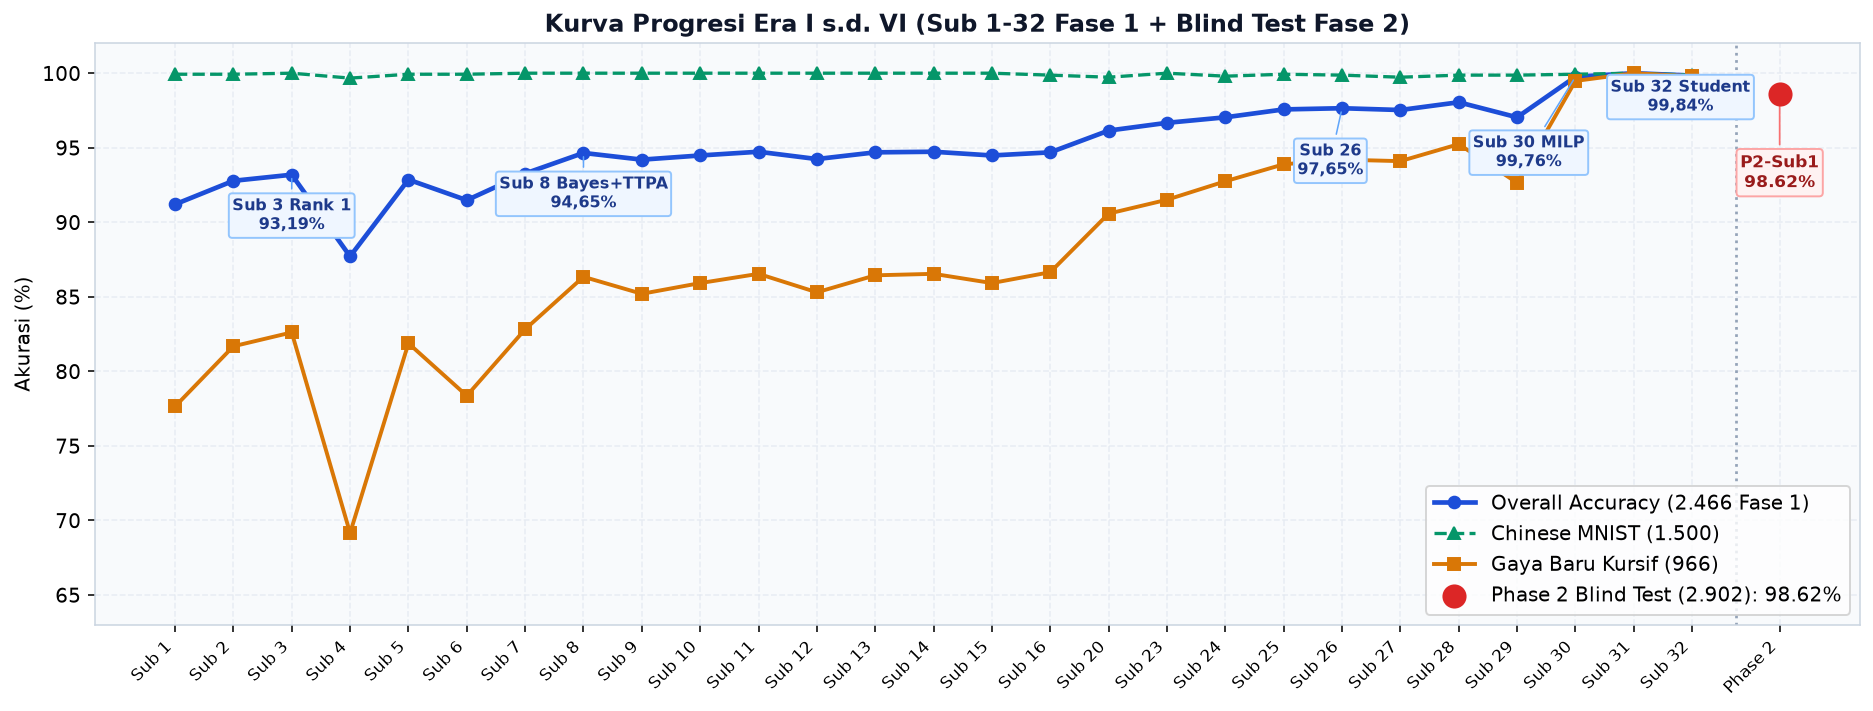

In [3]:
cols = ["sub_num", "filename", "status", "total_correct", "accuracy", "acc_chinese", "acc_gb_micro", "acc_target_macro"]
print("=== TABEL LINTASAN SUBMISSION CODABENCH TERVERIFIKASI ===")
print(df_subs[cols].to_string(index=False))

p1 = df_subs[df_subs["sub_num"] <= 32].copy()
p2_row = df_subs[df_subs["sub_num"] > 100].iloc[0]

fig, ax = plt.subplots(figsize=(13.5, 5.2), dpi=140)
x = np.arange(len(p1))
ax.plot(x, p1["accuracy"] * 100, color="#1D4ED8", marker="o", lw=2.4, label="Overall Accuracy (2.466 Fase 1)")
ax.plot(x, p1["acc_chinese"] * 100, color="#059669", linestyle="--", marker="^", lw=1.7, label="Chinese MNIST (1.500)")
ax.plot(x, p1["acc_gb_micro"] * 100, color="#D97706", marker="s", lw=2.0, label="Gaya Baru Kursif (966)")

# Tambahkan titik Phase 2 Blind Test di posisi paling kanan
x_p2 = len(p1) + 0.5
ax.scatter([x_p2], [p2_row["accuracy"] * 100], color="#DC2626", s=130, zorder=5, label=f"Phase 2 Blind Test (2.902): {p2_row['accuracy']*100:.2f}%")
ax.axvline(len(p1) - 0.25, color="#94A3B8", linestyle=":", lw=1.4)

labels = [f"Sub {int(s)}" for s in p1["sub_num"]] + ["Phase 2"]
ax.set_xticks(list(x) + [x_p2])
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8.5)
ax.set_ylim(63, 102)
ax.set_ylabel("Akurasi (%)")
ax.set_title("Kurva Progresi Era I s.d. VI (Sub 1-32 Fase 1 + Blind Test Fase 2)", fontweight="bold", color="#0F172A")

highlights = {
    3: ("Sub 3 Rank 1\n93,19%", (0, -28)),
    8: ("Sub 8 Bayes+TTPA\n94,65%", (0, -28)),
    26: ("Sub 26\n97,65%", (-6, -34)),
    30: ("Sub 30 MILP\n99,76%", (-24, -46)),
    32: ("Sub 32 Student\n99,84%", (-6, -18)),
}
for i, row in p1.iterrows():
    s = int(row["sub_num"])
    if s in highlights:
        txt, offset = highlights[s]
        xi = p1.index.get_loc(i)
        ax.annotate(txt, (xi, row["accuracy"] * 100), textcoords="offset points", xytext=offset,
                    ha="center", fontsize=8, fontweight="bold", color="#1E3A8A",
                    arrowprops=dict(arrowstyle="-", color="#60A5FA", lw=0.8),
                    bbox=dict(boxstyle="round,pad=0.22", fc="#EFF6FF", ec="#93C5FD"))

ax.annotate(f"P2-Sub1\n{p2_row['accuracy']*100:.2f}%", (x_p2, p2_row["accuracy"] * 100),
            textcoords="offset points", xytext=(0, -48), ha="center", fontsize=8.5, fontweight="bold",
            color="#991B1B", arrowprops=dict(arrowstyle="-", color="#F87171", lw=0.9),
            bbox=dict(boxstyle="round,pad=0.22", fc="#FEF2F2", ec="#FCA5A5"))
ax.legend(loc="lower right", frameon=True, facecolor="#FFFFFF")
plt.tight_layout()
plt.show()

## 3. Analisis Kemajuan Per-Kelas pada Sub-Domain Kaligrafi Gaya Baru (966 Citra)

Menunjukkan bagaimana kelas tersulit di Fase 1 (terutama Kelas `4` `Si`, `5` `Wu`, `11` `Bai`, `12` `Qian`, dan `13` `Wan`) melonjak dari baseline `Sub 1` / `Sub 3` ke `Sub 26` setelah integrasi **DenseNet-CBAM**, **Augmentasi Biomekanik**, **MixStyle**, dan **TTPA**.

=== AKURASI GAYA BARU PER KELAS AKTIF (KELAS 0 & 14 = 0 SAMPEL DI GAYA BARU 966) ===
        Kelas  Sub 1 AdaBN (%)  Sub 3 Blend (%)  Sub 8 Bayes+TTPA (%)  Sub 26 (%)  Delta (Sub26 - Sub1)
   Kls 1 (Yi)             96.0             97.0                  97.0        97.0                   1.0
   Kls 2 (Er)             96.0             98.0                  97.0        99.0                   3.0
  Kls 3 (San)             92.0             95.0                  96.0        98.0                   6.0
   Kls 4 (Si)             59.0             73.0                  94.0        99.0                  40.0
   Kls 5 (Wu)             45.0             51.0                  59.0        83.0                  38.0
  Kls 6 (Liu)             79.0             81.0                  87.0        83.0                   4.0
   Kls 7 (Qi)             90.6             96.9                  96.9        98.4                   7.8
   Kls 8 (Ba)             98.4             98.4                  98.4        98.4  

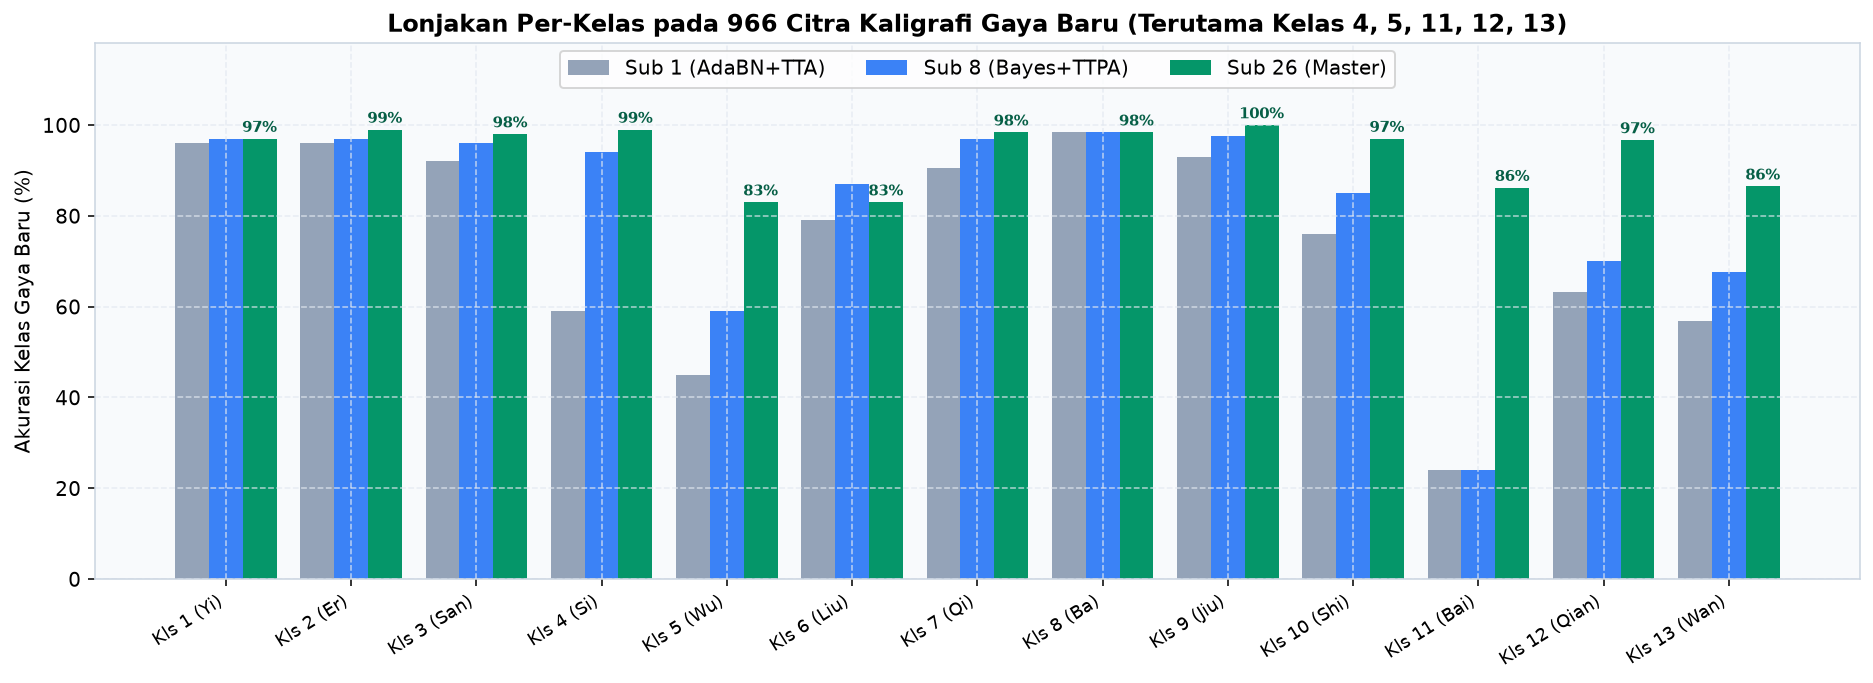

In [4]:
bd = verified["codabench_class_breakdown"]
classes_active = [str(c) for c in range(1, 14)]  # Kelas 0 dan 14 absen di Gaya Baru 966 (None)
class_names = {
    "1": "Kls 1 (Yi)", "2": "Kls 2 (Er)", "3": "Kls 3 (San)", "4": "Kls 4 (Si)",
    "5": "Kls 5 (Wu)", "6": "Kls 6 (Liu)", "7": "Kls 7 (Qi)", "8": "Kls 8 (Ba)",
    "9": "Kls 9 (Jiu)", "10": "Kls 10 (Shi)", "11": "Kls 11 (Bai)", "12": "Kls 12 (Qian)",
    "13": "Kls 13 (Wan)",
}

rows_cls = []
for c in classes_active:
    rows_cls.append({
        "Kelas": class_names[c],
        "Sub 1 AdaBN (%)": bd["sub_1"]["gb_class_acc_pct"][c],
        "Sub 3 Blend (%)": bd["sub_3"]["gb_class_acc_pct"][c],
        "Sub 8 Bayes+TTPA (%)": bd["sub_8"]["gb_class_acc_pct"][c],
        "Sub 26 (%)": bd["sub_26"]["gb_class_acc_pct"][c],
    })
df_cls = pd.DataFrame(rows_cls)
df_cls["Delta (Sub26 - Sub1)"] = df_cls["Sub 26 (%)"] - df_cls["Sub 1 AdaBN (%)"]
print("=== AKURASI GAYA BARU PER KELAS AKTIF (KELAS 0 & 14 = 0 SAMPEL DI GAYA BARU 966) ===")
print(df_cls.to_string(index=False))

fig, ax = plt.subplots(figsize=(13.5, 5.0), dpi=140)
x = np.arange(len(classes_active))
w = 0.27
ax.bar(x - w, df_cls["Sub 1 AdaBN (%)"], width=w, color="#94A3B8", label="Sub 1 (AdaBN+TTA)")
ax.bar(x, df_cls["Sub 8 Bayes+TTPA (%)"], width=w, color="#3B82F6", label="Sub 8 (Bayes+TTPA)")
ax.bar(x + w, df_cls["Sub 26 (%)"], width=w, color="#059669", label="Sub 26 (Master)")

ax.set_xticks(x)
ax.set_xticklabels(df_cls["Kelas"], rotation=32, ha="right", fontsize=9)
ax.set_ylim(0, 118)
ax.set_ylabel("Akurasi Kelas Gaya Baru (%)")
ax.set_title("Lonjakan Per-Kelas pada 966 Citra Kaligrafi Gaya Baru (Terutama Kelas 4, 5, 11, 12, 13)", fontweight="bold")
for idx, v in enumerate(df_cls["Sub 26 (%)"]):
    ax.text(idx + w, v + 1.5, f"{v:.0f}%", ha="center", fontsize=7.8, fontweight="bold", color="#065F46")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.005), ncol=3, frameon=True, facecolor="#FFFFFF")
plt.tight_layout()
plt.show()

## 4. Stress Test Ketahanan Derau, Kompresi Memori & Audit SWA vs Epoch-13

Memverifikasi keandalan **Single Student SWA FP16 (`14,75 MiB`)** terhadap derau Gaussian `sigma=25`, erosi/dilasi `2x2`, dan distorsi elastis dibandingkan guru sebelum distilasi, beserta perbandingan stabilitas SWA vs Epoch-13 pada Phase 2 (`2.902` citra).

=== EFISIENSI KOMPRESI PENYIMPANAN ===
Teacher Pool Phase 1 (26 ckpt) : 773.94 MiB
Adapted 15-Model Ensemble      : 444.55 MiB
Student FP32 Epoch-13          : 29.28 MiB
Final Student SWA FP16         : 14.75 MiB (Inferensi Fase 2: 5.44 s)
Noise Stability P2 (sigma=25)  : SWA=95.98% +/- 0.02% vs Ep13=94.37%


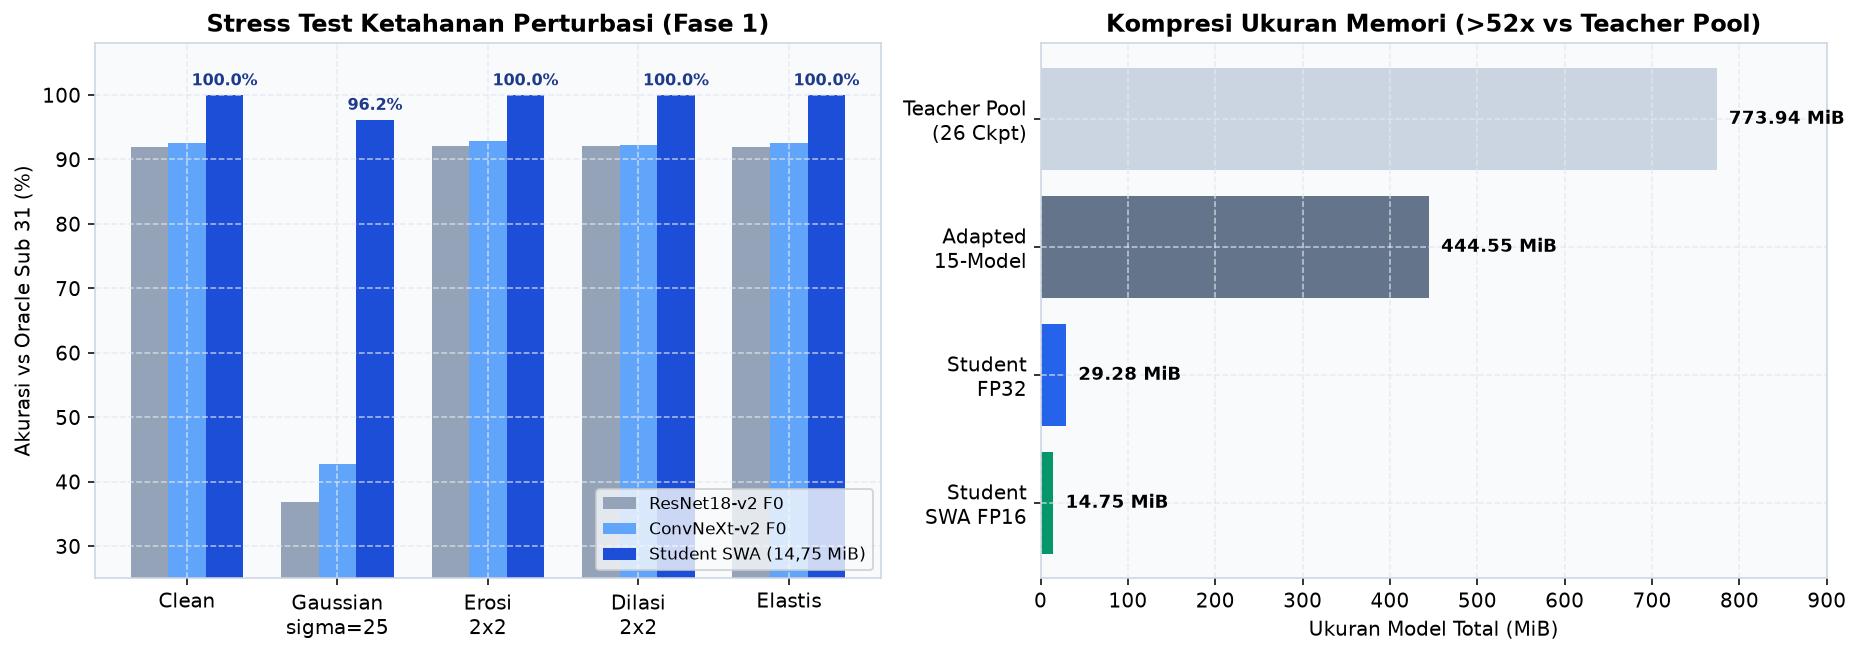

In [5]:
fp = verified["footprints_mb"]
st = verified["phase1_stress_test_vs_sub31"]
p2 = verified["phase2_verified"]

print("=== EFISIENSI KOMPRESI PENYIMPANAN ===")
print(f"Teacher Pool Phase 1 (26 ckpt) : {fp['all_phase1_teacher_ckpts_mb']:.2f} MiB")
print(f"Adapted 15-Model Ensemble      : {fp['adapted_15model_mb']:.2f} MiB")
print(f"Student FP32 Epoch-13          : {fp['student_ep13_fp32_mb']:.2f} MiB")
print(f"Final Student SWA FP16         : {fp['student_swa_fp16_mb']:.2f} MiB (Inferensi Fase 2: {p2['student_batch128_time_sec']:.2f} s)")
print(
    f"Noise Stability P2 (sigma=25)  : SWA={p2['swa_noise_s25_stability']['mean_stability_pct']:.2f}% +/- "
    f"{p2['swa_noise_s25_stability']['std_stability_pct']:.2f}% vs Ep13={p2['ep13_noise_s25_stability']['mean_stability_pct']:.2f}%"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=140)
cond_keys = ["clean", "gaussian_noise_s25", "stroke_erosion_2x2", "stroke_dilation_2x2", "elastic_distortion"]
cond_names = ["Clean", "Gaussian\nsigma=25", "Erosi\n2x2", "Dilasi\n2x2", "Elastis"]
xc = np.arange(len(cond_keys))
w = 0.25

s_vals = [st[k]["student_swa"]["overall"] for k in cond_keys]
r_vals = [st[k]["resnet18_v2_f0"]["overall"] for k in cond_keys]
c_vals = [st[k]["convnext_v2_f0"]["overall"] for k in cond_keys]

ax1.bar(xc - w, r_vals, width=w, color="#94A3B8", label="ResNet18-v2 F0")
ax1.bar(xc, c_vals, width=w, color="#60A5FA", label="ConvNeXt-v2 F0")
ax1.bar(xc + w, s_vals, width=w, color="#1D4ED8", label="Student SWA (14,75 MiB)")
ax1.set_xticks(xc)
ax1.set_xticklabels(cond_names)
ax1.set_ylim(25, 108)
ax1.set_ylabel("Akurasi vs Oracle Sub 31 (%)")
ax1.set_title("Stress Test Ketahanan Perturbasi (Fase 1)", fontweight="bold")
for i, v in enumerate(s_vals):
    ax1.text(i + w, v + 1.5, f"{v:.1f}%", ha="center", fontsize=8, fontweight="bold", color="#1E3A8A")
ax1.legend(loc="lower right", fontsize=8.5)

arch_labels = ["Teacher Pool\n(26 Ckpt)", "Adapted\n15-Model", "Student\nFP32", "Student\nSWA FP16"]
arch_mb = [
    fp["all_phase1_teacher_ckpts_mb"],
    fp["adapted_15model_mb"],
    fp["student_ep13_fp32_mb"],
    fp["student_swa_fp16_mb"],
]
bars = ax2.barh(arch_labels[::-1], arch_mb[::-1], color=["#059669", "#2563EB", "#64748B", "#CBD5E1"])
ax2.set_xlabel("Ukuran Model Total (MiB)")
ax2.set_title("Kompresi Ukuran Memori (>52x vs Teacher Pool)", fontweight="bold")
for bar, val in zip(bars, arch_mb[::-1]):
    ax2.text(val + 14, bar.get_y() + bar.get_height() / 2, f"{val:.2f} MiB", va="center", fontweight="bold", fontsize=9)
ax2.set_xlim(0, 900)
plt.tight_layout()
plt.show()

## 5. Kurva Kalibrasi Keyakinan (Fase 1 & Distribusi Keyakinan Fase 2)

Mengaudit kecenderungan **overconfidence** model praproses awal (`ECE = 5,18%`, `Brier = 0,1276`) dibandingkan Student SWA (`ECE = 0,00%` di Fase 1), serta profil keyakinan pada `2.902` citra blind test Fase 2 sebelum dan sesudah adaptasi prior Bayesian (`EM TTPA`, entropi rata-rata `0,00480`).

=== KALIBRASI FASE 1 & FASE 2 ===
ResNet18-v2 Fold 0 (Pre-KD) : ECE=5.18% | Brier=0.1276
Distilled Student SWA       : ECE=0.00% | Brier=0.0000
Phase 2 (2.902 citra)       : Raw max_p >= 0.99: 2847 | +TTPA max_p >= 0.99: 2872 | Mean Entropy=0.00480


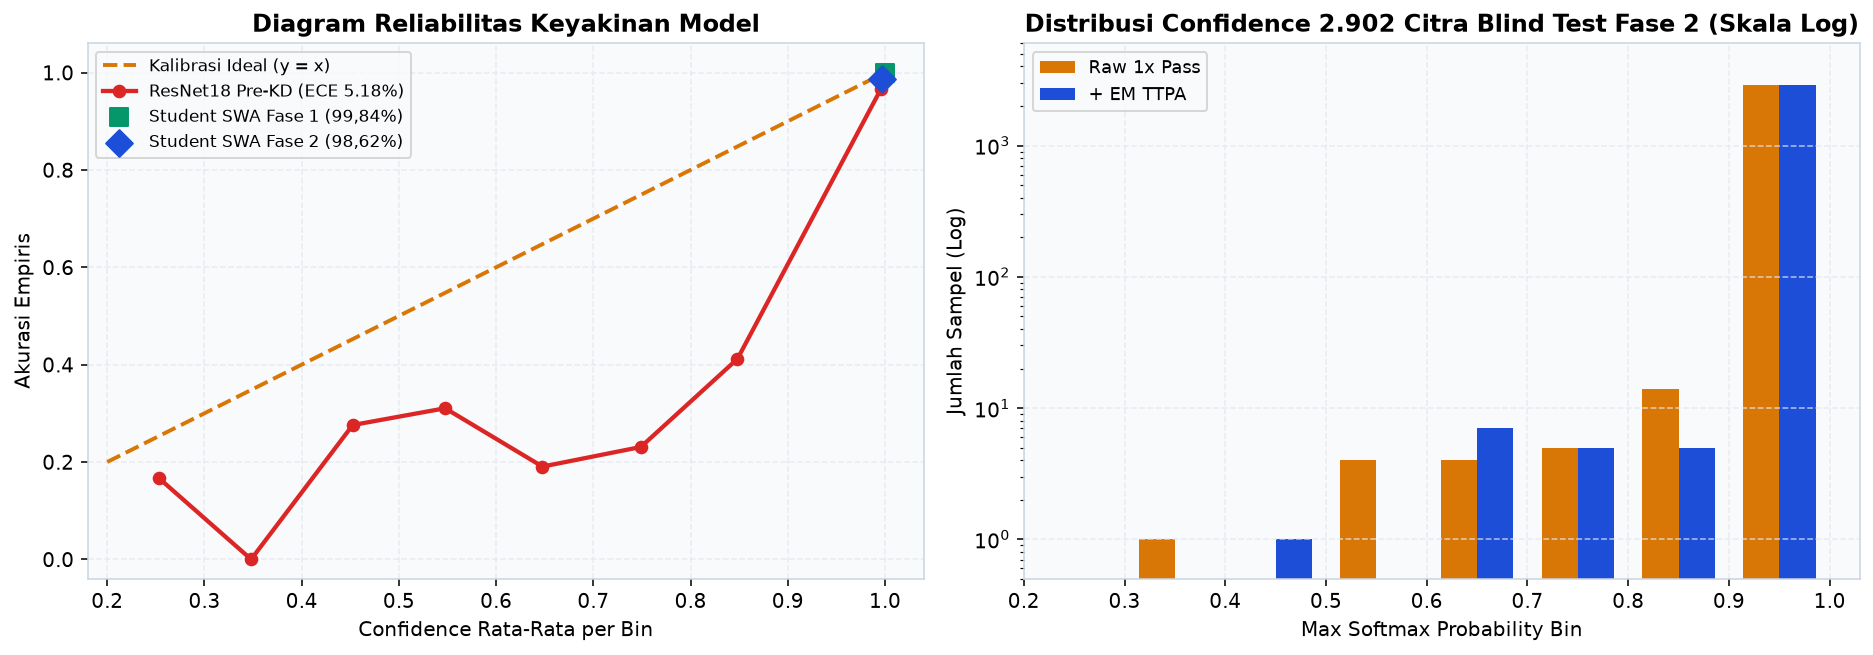

In [6]:
rel = verified["phase1_reliability"]
p2 = verified["phase2_verified"]
base_bins = rel["resnet18_v2_fold0"]["bins"]

print("=== KALIBRASI FASE 1 & FASE 2 ===")
print(f"ResNet18-v2 Fold 0 (Pre-KD) : ECE={rel['resnet18_v2_fold0']['ece_pct']:.2f}% | Brier={rel['resnet18_v2_fold0']['brier']:.4f}")
print(f"Distilled Student SWA       : ECE={rel['student_swa']['ece_pct']:.2f}% | Brier={rel['student_swa']['brier']:.4f}")
print(
    f"Phase 2 (2.902 citra)       : Raw max_p >= 0.99: {p2['sub1_raw_maxp_gte_099']} | "
    f"+TTPA max_p >= 0.99: {p2['sub1_ttpa_maxp_gte_099']} | Mean Entropy={p2['sub1_ttpa_mean_entropy']:.5f}"
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=140)
confs = [b["conf"] for b in base_bins]
accs = [b["acc"] for b in base_bins]
ax1.plot([0.2, 1.0], [0.2, 1.0], linestyle="--", color="#D97706", lw=2, label="Kalibrasi Ideal (y = x)")
ax1.plot(confs, accs, color="#DC2626", marker="o", lw=2.2, label=f"ResNet18 Pre-KD (ECE {rel['resnet18_v2_fold0']['ece_pct']:.2f}%)")
ax1.scatter([1.0], [0.9984], color="#059669", marker="s", s=95, zorder=5, label="Student SWA Fase 1 (99,84%)")
ax1.scatter([0.9972], [0.9862], color="#1D4ED8", marker="D", s=95, zorder=5, label="Student SWA Fase 2 (98,62%)")
ax1.set_title("Diagram Reliabilitas Keyakinan Model", fontweight="bold")
ax1.set_xlabel("Confidence Rata-Rata per Bin")
ax1.set_ylabel("Akurasi Empiris")
ax1.set_xlim(0.18, 1.04)
ax1.set_ylim(-0.04, 1.06)
ax1.legend(loc="upper left", fontsize=8.5)

edges = np.arange(0.05, 1.05, 0.1)
raw_hist = p2["sub1_raw_10bin_hist"]
ttpa_hist = p2["sub1_ttpa_10bin_hist"]
ax2.bar(edges - 0.018, raw_hist, width=0.036, color="#D97706", label="Raw 1x Pass")
ax2.bar(edges + 0.018, ttpa_hist, width=0.036, color="#1D4ED8", label="+ EM TTPA")
ax2.set_yscale("log")
ax2.set_ylim(0.5, 6000)
ax2.set_xlim(0.2, 1.03)
ax2.set_title("Distribusi Confidence 2.902 Citra Blind Test Fase 2 (Skala Log)", fontweight="bold")
ax2.set_xlabel("Max Softmax Probability Bin")
ax2.set_ylabel("Jumlah Sampel (Log)")
ax2.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

## 6. Galeri Ringkas Infografik Arsitektur Utama (`outputs/presentation_figures/`)

Pratinjau 6 diagram arsitektur dan metodologi utama yang juga dimuat pada presentasi Keynote 29 slide (`FP_Analisis_Data_Multivariat_Tim_Arete_5025241135_FINAL.pdf`).

Semua sel evaluasi visual selesai dijalankan.


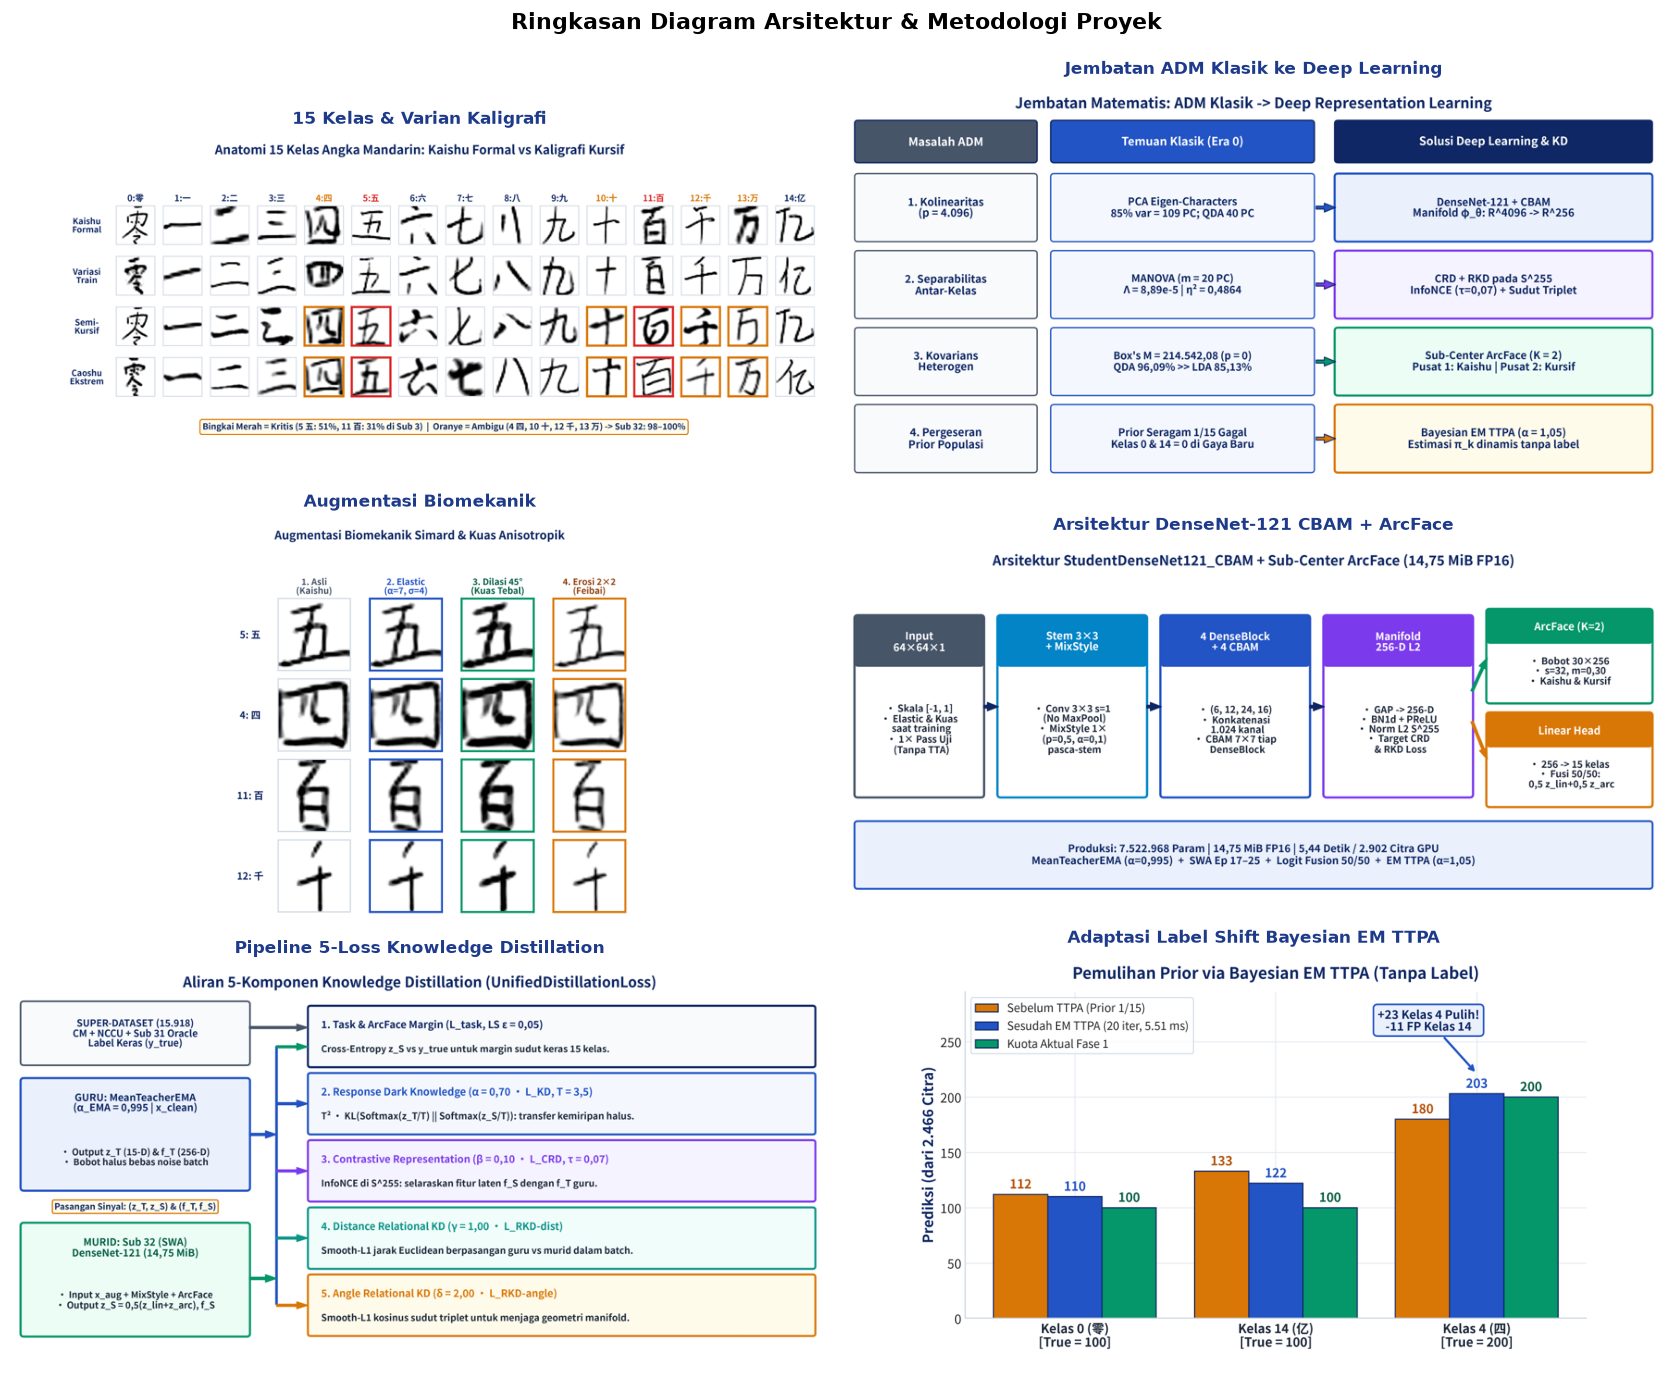

In [7]:
key_diagrams = [
    ("15 Kelas & Varian Kaligrafi", "info_15_classes_and_calligraphy.png"),
    ("Jembatan ADM Klasik ke Deep Learning", "info_adm_to_dl_bridge.png"),
    ("Augmentasi Biomekanik", "info_biomechanical_augmentation.png"),
    ("Arsitektur DenseNet-121 CBAM + ArcFace", "info_densenet_cbam_architecture.png"),
    ("Pipeline 5-Loss Knowledge Distillation", "info_kd_5loss_pipeline.png"),
    ("Adaptasi Label Shift Bayesian EM TTPA", "info_ttpa_prior_shift.png"),
]

fig, axes = plt.subplots(3, 2, figsize=(13.5, 11.0), dpi=125)
for ax, (title, fname) in zip(axes.flat, key_diagrams):
    fpath = FIG_DIR / fname
    img = Image.open(fpath).convert("RGB")
    img.thumbnail((880, 520))
    ax.imshow(img)
    ax.set_title(title, fontsize=10, fontweight="bold", color="#1E3A8A")
    ax.axis("off")

plt.suptitle("Ringkasan Diagram Arsitektur & Metodologi Proyek", fontsize=12.5, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()
print("Semua sel evaluasi visual selesai dijalankan.")